# Notebook 02 - Modelagem, MLflow Tracking e Model Registry

## Objetivo
Treinar e comparar 3 modelos de regressão para prever a vazão defluente (`val_vazaodefluente`)
da Usina de Balbina, utilizando MLflow para rastreamento dos experimentos e registro
do modelo vencedor em producao.

## Modelos comparados:
1. LinearRegression (baseline)
2. RandomForestRegressor
3. GradientBoostingRegressor (modelo principal)

## Metrica principal: RMSE (Root Mean Squared Error)
## Metricas secundarias: MAE, R²

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [2]:
import os
from pathlib import Path

ROOT = Path().resolve().parent
mlflow.set_tracking_uri(f"file:///{ROOT}/mlruns".replace("\\", "/"))
mlflow.set_experiment("balbina_vazao_defluente_v2")
print("Tracking URI:", mlflow.get_tracking_uri())

Tracking URI: file:///C:/projetos-estudo/balbina-hydro-mlops/mlruns


## 1. Carregamento dos dados processados

In [3]:
# Carregar dataset processado
df = pd.read_csv("../data/processed/balbina_processado.csv", sep=";", encoding="utf-8-sig")

print("Shape:", df.shape)
print("\nPrimeiras linhas:")
print(df.head())

# Separar features e alvo
X = df.drop(columns=["val_vazaodefluente"])
y = df["val_vazaodefluente"]

print(f"\nFeatures: {list(X.columns)}")
print(f"Alvo: val_vazaodefluente")
print(f"Total de registros: {len(df):,}")

Shape: (12077, 7)

Primeiras linhas:
   val_nivelmontante  val_niveljusante  val_vazaoafluente  val_vazaodefluente  \
0              46.04             24.60              287.0               284.0   
1              46.04             24.59              287.0               284.0   
2              46.04             24.59              287.0               284.0   
3              46.04             24.60              287.0               284.0   
4              46.04             24.59              287.0               284.0   

   mes  dia  hora  
0    1    1     1  
1    1    1     2  
2    1    1     3  
3    1    1     4  
4    1    1     5  

Features: ['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'mes', 'dia', 'hora']
Alvo: val_vazaodefluente
Total de registros: 12,077


## 2. Divisão Treino/Teste e Pipeline

In [4]:
# Divisão treino/teste (80/20) sem embaralhamento - dados temporais
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=False
)

print(f"Treino : {X_train.shape[0]:,} registros")
print(f"Teste  : {X_test.shape[0]:,} registros")

# Pipeline de pré-processamento
features_num = list(X.columns)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), features_num),
])

print("\nPipeline de pre-processamento configurado!")
print(f"Features numericas: {features_num}")

Treino : 9,661 registros
Teste  : 2,416 registros

Pipeline de pre-processamento configurado!
Features numericas: ['val_nivelmontante', 'val_niveljusante', 'val_vazaoafluente', 'mes', 'dia', 'hora']


## 3. Treinamento dos 3 Modelos com MLflow Tracking

In [5]:
# Configurar MLflow
mlflow.set_tracking_uri("../mlruns")
mlflow.set_experiment("balbina_vazao_defluente_v2")

def avaliar_modelo(nome, pipeline, X_train, X_test, y_train, y_test):
    """Treina, avalia e loga um modelo no MLflow."""
    
    with mlflow.start_run(run_name=nome):
        # Validação cruzada (5-fold)
        cv_results = cross_validate(
            pipeline, X_train, y_train,
            cv=5,
            scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"],
            return_train_score=False
        )
        
        rmse_cv  = -cv_results["test_neg_root_mean_squared_error"].mean()
        rmse_std = cv_results["test_neg_root_mean_squared_error"].std()
        mae_cv   = -cv_results["test_neg_mean_absolute_error"].mean()
        r2_cv    = cv_results["test_r2"].mean()
        
        # Treinar no conjunto completo de treino
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        
        rmse_test = root_mean_squared_error(y_test, y_pred)
        mae_test  = mean_absolute_error(y_test, y_pred)
        r2_test   = r2_score(y_test, y_pred)
        
        # Logar métricas e modelo no MLflow
        mlflow.log_param("modelo", nome)
        mlflow.log_metric("rmse_cv_media", round(rmse_cv, 4))
        mlflow.log_metric("rmse_cv_std",   round(rmse_std, 4))
        mlflow.log_metric("mae_cv",        round(mae_cv, 4))
        mlflow.log_metric("r2_cv",         round(r2_cv, 4))
        mlflow.log_metric("rmse_test",     round(rmse_test, 4))
        mlflow.log_metric("mae_test",      round(mae_test, 4))
        mlflow.log_metric("r2_test",       round(r2_test, 4))
        mlflow.sklearn.log_model(pipeline, name="model")
        
        print(f"\n{'='*45}")
        print(f"Modelo : {nome}")
        print(f"RMSE CV : {rmse_cv:.2f} (+/- {rmse_std:.2f})")
        print(f"MAE  CV : {mae_cv:.2f}")
        print(f"R²   CV : {r2_cv:.4f}")
        print(f"RMSE Teste: {rmse_test:.2f}")
        print(f"R²   Teste: {r2_test:.4f}")
        
        return pipeline, y_pred

print("Funcao de avaliacao configurada!")

Funcao de avaliacao configurada!


## 3.1 Modelo 1 - Linear Regression (Baseline)

In [6]:
pipe_lr = Pipeline([
    ("pre", preprocessor),
    ("clf", LinearRegression())
])

modelo_lr, pred_lr = avaliar_modelo(
    "LinearRegression", pipe_lr, X_train, X_test, y_train, y_test
)

2026/05/30 08:44:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Modelo : LinearRegression
RMSE CV : 107.74 (+/- 24.19)
MAE  CV : 77.99
R²   CV : 0.8172
RMSE Teste: 182.34
R²   Teste: 0.7643


## 3.2 Modelo 2 - Random Forest Regressor

In [7]:
pipe_rf = Pipeline([
    ("pre", preprocessor),
    ("clf", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

modelo_rf, pred_rf = avaliar_modelo(
    "RandomForestRegressor", pipe_rf, X_train, X_test, y_train, y_test
)

2026/05/30 08:44:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Modelo : RandomForestRegressor
RMSE CV : 90.05 (+/- 28.96)
MAE  CV : 55.39
R²   CV : 0.8925
RMSE Teste: 162.98
R²   Teste: 0.8117


## 3.3 Modelo 3 - Gradient Boosting Regressor

In [8]:
pipe_gb = Pipeline([
    ("pre", preprocessor),
    ("clf", GradientBoostingRegressor(n_estimators=100, random_state=42))
])

modelo_gb, pred_gb = avaliar_modelo(
    "GradientBoostingRegressor", pipe_gb, X_train, X_test, y_train, y_test
)

2026/05/30 08:45:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Modelo : GradientBoostingRegressor
RMSE CV : 83.26 (+/- 24.41)
MAE  CV : 54.75
R²   CV : 0.9043
RMSE Teste: 160.96
R²   Teste: 0.8163


## 4. Comparativo dos 3 Modelos

                   Modelo  RMSE_CV  RMSE_CV_std  MAE_CV  R2_CV  RMSE_Teste  R2_Teste
         LinearRegression   107.74        24.19   77.99 0.8172      182.34    0.7643
    RandomForestRegressor    90.05        28.96   55.39 0.8925      162.98    0.8117
GradientBoostingRegressor    83.26        24.41   54.75 0.9043      160.96    0.8163


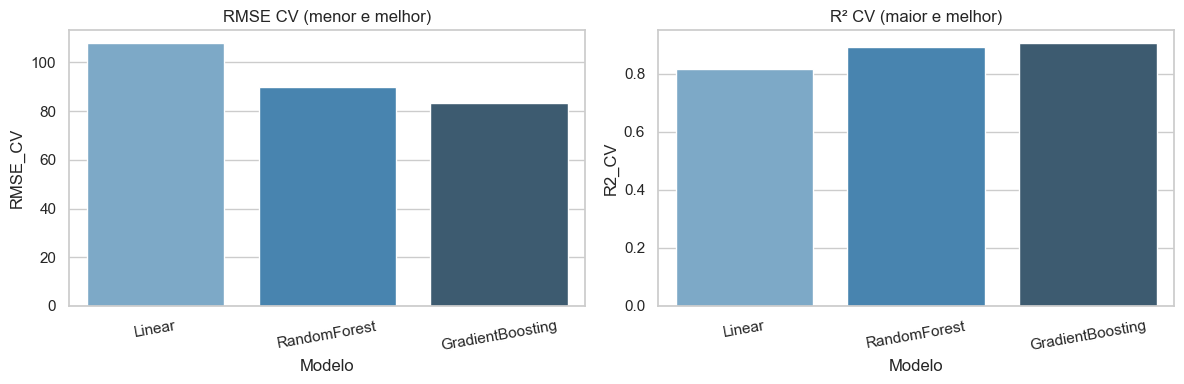

In [9]:
# Tabela comparativa
resultados = pd.DataFrame({
    "Modelo": ["LinearRegression", "RandomForestRegressor", "GradientBoostingRegressor"],
    "RMSE_CV": [107.74, 90.05, 83.26],
    "RMSE_CV_std": [24.19, 28.96, 24.41],
    "MAE_CV": [77.99, 55.39, 54.75],
    "R2_CV": [0.8172, 0.8925, 0.9043],
    "RMSE_Teste": [182.34, 162.98, 160.96],
    "R2_Teste": [0.7643, 0.8117, 0.8163],
})

print(resultados.to_string(index=False))

# Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=resultados, x="Modelo", y="RMSE_CV", ax=axes[0], palette="Blues_d")
axes[0].set_title("RMSE CV (menor e melhor)")
axes[0].set_xticklabels(["Linear", "RandomForest", "GradientBoosting"], rotation=10)

sns.barplot(data=resultados, x="Modelo", y="R2_CV", ax=axes[1], palette="Blues_d")
axes[1].set_title("R² CV (maior e melhor)")
axes[1].set_xticklabels(["Linear", "RandomForest", "GradientBoosting"], rotation=10)

plt.tight_layout()
plt.savefig("../notebooks/fig_comparativo_modelos.png", dpi=150)
plt.show()

## 5. Tuning do Modelo Vencedor - GradientBoostingRegressor

In [10]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [3, 4, 5],
    "clf__learning_rate": [0.05, 0.1, 0.2],
    "clf__subsample": [0.8, 1.0],
}

pipe_gb_tuning = Pipeline([
    ("pre", preprocessor),
    ("clf", GradientBoostingRegressor(random_state=42))
])

search = RandomizedSearchCV(
    pipe_gb_tuning,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print(f"\nMelhores parametros:")
print(search.best_params_)
print(f"\nMelhor RMSE CV: {-search.best_score_:.2f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Melhores parametros:
{'clf__subsample': 1.0, 'clf__n_estimators': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.1}

Melhor RMSE CV: 83.26


## 5.1 Registrando modelo tunado no MLflow

In [11]:
# Avaliar modelo tunado no conjunto de teste
y_pred_tuned = search.best_estimator_.predict(X_test)
rmse_tuned = root_mean_squared_error(y_test, y_pred_tuned)
mae_tuned  = mean_absolute_error(y_test, y_pred_tuned)
r2_tuned   = r2_score(y_test, y_pred_tuned)

print(f"Modelo tunado - Teste:")
print(f"  RMSE : {rmse_tuned:.2f}")
print(f"  MAE  : {mae_tuned:.2f}")
print(f"  R²   : {r2_tuned:.4f}")

# Logar no MLflow
with mlflow.start_run(run_name="GradientBoosting_Tuned"):
    mlflow.log_param("modelo", "GradientBoostingRegressor_Tuned")
    for param, valor in search.best_params_.items():
        mlflow.log_param(param, valor)
    mlflow.log_metric("rmse_cv",   round(-search.best_score_, 4))
    mlflow.log_metric("rmse_test", round(rmse_tuned, 4))
    mlflow.log_metric("mae_test",  round(mae_tuned, 4))
    mlflow.log_metric("r2_test",   round(r2_tuned, 4))
    mlflow.sklearn.log_model(search.best_estimator_, name="model")
    run_id = mlflow.active_run().info.run_id
    print(f"\nRun ID: {run_id}")
    print("Modelo tunado logado no MLflow!")

2026/05/30 08:45:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modelo tunado - Teste:
  RMSE : 160.96
  MAE  : 95.93
  R²   : 0.8163

Run ID: 93fa005e10754b39af15a1f7be4dce15
Modelo tunado logado no MLflow!


## 6. Gráfico Predito vs Real

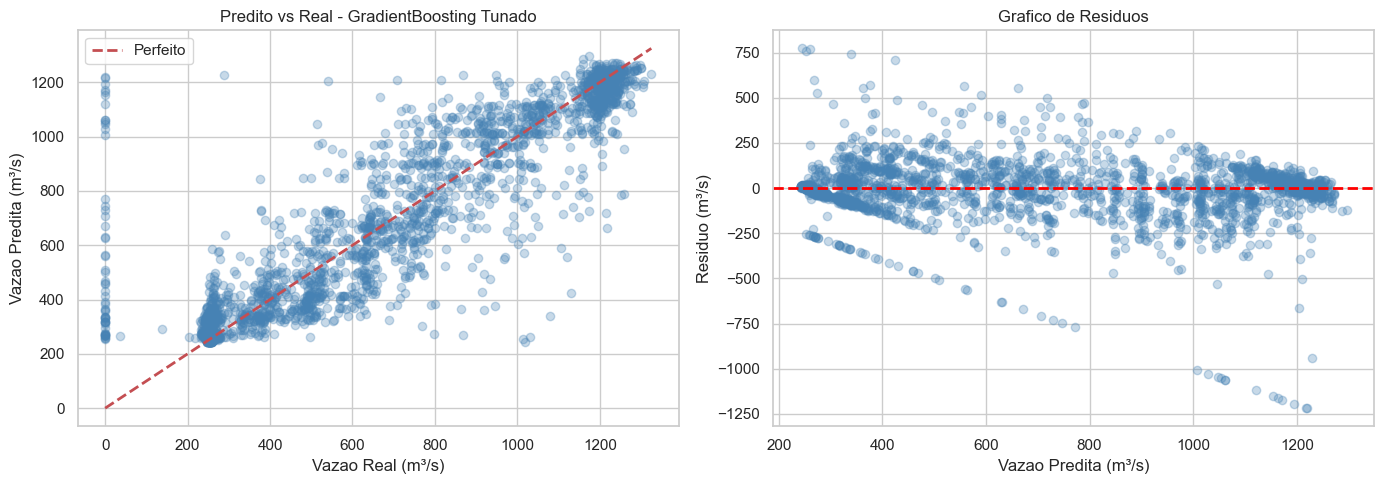

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatterplot predito vs real
axes[0].scatter(y_test, y_pred_tuned, alpha=0.3, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], 
             [y_test.min(), y_test.max()], 
             "r--", linewidth=2, label="Perfeito")
axes[0].set_xlabel("Vazao Real (m³/s)")
axes[0].set_ylabel("Vazao Predita (m³/s)")
axes[0].set_title("Predito vs Real - GradientBoosting Tunado")
axes[0].legend()

# Resíduos
residuos = y_test - y_pred_tuned
axes[1].scatter(y_pred_tuned, residuos, alpha=0.3, color="steelblue")
axes[1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_xlabel("Vazao Predita (m³/s)")
axes[1].set_ylabel("Residuo (m³/s)")
axes[1].set_title("Grafico de Residuos")

plt.tight_layout()
plt.savefig("../notebooks/fig_predito_vs_real.png", dpi=150)
plt.show()

## 7. Model Registry - Promovendo o modelo vencedor para @production

In [13]:
# Logar artefatos no run do modelo tunado
with mlflow.start_run(run_id=run_id):
    mlflow.log_artifact("../notebooks/fig_predito_vs_real.png")
    mlflow.log_artifact("../notebooks/fig_comparativo_modelos.png")
    print("Artefatos logados!")

# Registrar no Model Registry
from pathlib import Path
ROOT = Path().resolve().parent
TRACKING_URI = f"file:///{ROOT}/mlruns".replace("\\", "/")
cliente = MlflowClient(tracking_uri=TRACKING_URI)
NOME_MODELO = "previsor_vazao_balbina"

# Criar modelo registrado
try:
    cliente.create_registered_model(NOME_MODELO)
    print(f"Modelo '{NOME_MODELO}' criado no Registry!")
except Exception:
    print(f"Modelo '{NOME_MODELO}' ja existe no Registry.")

# Buscar URI do artefato do run tunado
run = cliente.get_run(run_id)
artifact_uri = run.info.artifact_uri + "/model"
print(f"Artifact URI: {artifact_uri}")

# Criar versão
versao = cliente.create_model_version(
    name=NOME_MODELO,
    source=artifact_uri,
    run_id=run_id
)
print(f"Versao {versao.version} criada!")

# Atribuir alias @production
cliente.set_registered_model_alias(NOME_MODELO, "production", versao.version)
print(f"Alias @production atribuido a versao {versao.version}!")

Artefatos logados!
Modelo 'previsor_vazao_balbina' ja existe no Registry.
Artifact URI: file:///C:/projetos-estudo/balbina-hydro-mlops/mlruns/737769590242991027/93fa005e10754b39af15a1f7be4dce15/artifacts/model
Versao 15 criada!
Alias @production atribuido a versao 15!
